# Olist E-Commerce: Exploratory Analysis and Business Insights

**Goal:** understand what drives revenue, customer satisfaction and retention for a Brazilian online marketplace, and turn the answers into recommendations.

**Approach:** raw CSVs -> SQLite database -> SQL views/queries (single source of truth for metric definitions) -> pandas / scikit-learn for statistics and modelling.

> Run `python run_pipeline.py` first so the database exists. All numbers in this notebook are computed live from it.

In [1]:
import sqlite3, warnings
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:,.2f}".format, "display.width", 140)
sns.set_theme(style="whitegrid", context="notebook")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
con = sqlite3.connect(ROOT / "data" / "olist.db")
q = lambda sql: pd.read_sql_query(sql, con)
SYNTHETIC = (ROOT / "data" / "raw" / "_SYNTHETIC_DATA.txt").exists()
print("Using SYNTHETIC demo data" if SYNTHETIC else "Using real Olist data")

Using real Olist data


## 1. Data overview and quality
Row counts per table and null rates for the columns that matter.

In [2]:
tables = ["customers","orders","order_items","order_payments","order_reviews","products","sellers","geolocation","category_translation"]
pd.DataFrame({"rows":[q(f"SELECT COUNT(*) n FROM {t}")["n"][0] for t in tables]}, index=tables)

,rows
customers,99441
orders,99441
order_items,112650
order_payments,103886
order_reviews,99224
products,32951
sellers,3095
geolocation,1000163
category_translation,71


In [3]:
checks = {
 "orders missing approval timestamp": "SELECT COUNT(*) FROM orders WHERE order_approved_at IS NULL",
 "delivered orders without delivery date": "SELECT COUNT(*) FROM orders WHERE order_status='delivered' AND order_delivered_customer_date IS NULL",
 "delivered BEFORE purchase (impossible)": "SELECT COUNT(*) FROM orders WHERE order_delivered_customer_date < order_purchase_timestamp",
 "products without category": "SELECT COUNT(*) FROM products WHERE product_category_name IS NULL",
 "items with price <= 0": "SELECT COUNT(*) FROM order_items WHERE price <= 0",
 "orders with more than one review": "SELECT COUNT(*) FROM (SELECT order_id FROM order_reviews GROUP BY order_id HAVING COUNT(*)>1)",
 "orders with no line items": "SELECT COUNT(*) FROM orders WHERE order_id NOT IN (SELECT order_id FROM order_items)",
}
pd.Series({k: con.execute(v).fetchone()[0] for k, v in checks.items()}, name="count").to_frame()

,count
orders missing approval timestamp,160
delivered orders without delivery date,8
delivered BEFORE purchase (impossible),0
products without category,610
items with price <= 0,0
orders with more than one review,547
orders with no line items,775


**Cleaning decisions**
- Canceled / unavailable orders are excluded from revenue metrics.
- Orders with several reviews keep only the latest (view `v_order_review`).
- Products without a category are labelled `unknown` rather than dropped, to keep revenue totals complete.
- `customer_id` is generated per order; every customer metric uses `customer_unique_id`.

## 2. Headline KPIs

In [4]:
pd.read_csv(ROOT/"data/processed/sql_kpi_summary.csv").T.rename(columns={0:"value"})

,value
total_orders,"99,441.00"
valid_orders,"98,199.00"
unique_customers,"94,983.00"
revenue,"13,494,400.74"
avg_order_value,137.42
avg_review_score,4.12
late_delivery_pct,8.11
avg_delivery_days,12.56
repeat_customer_pct,3.04


## 3. Revenue trend

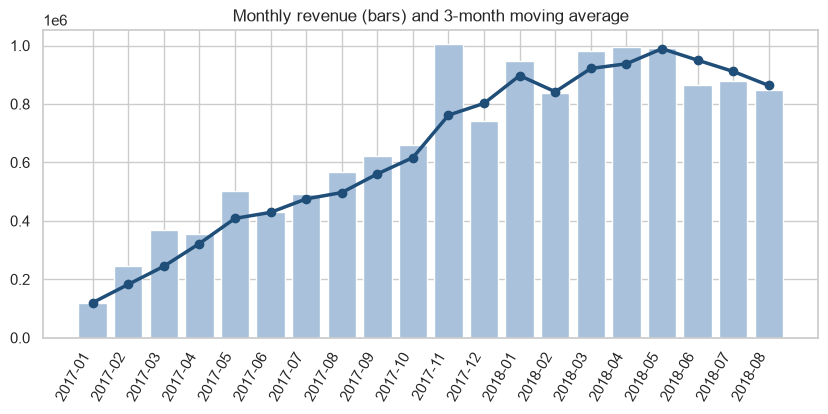

,purchase_month,revenue,revenue_mom_pct
1,2017-02,"244,959.35",104.00
10,2017-11,"1,003,862.14",52.10
2,2017-03,"368,341.32",50.40


In [5]:
m = pd.read_csv(ROOT/"data/processed/sql_monthly_revenue.csv")
fig, ax = plt.subplots(figsize=(10,4))
ax.bar(m.purchase_month, m.revenue, color="#A9C1DB"); ax.plot(m.purchase_month, m.revenue_3m_avg, color="#1F4E79", lw=2.5, marker="o")
ax.set_title("Monthly revenue (bars) and 3-month moving average"); plt.xticks(rotation=60, ha="right"); plt.show()
m.sort_values("revenue_mom_pct", ascending=False).head(3)[["purchase_month","revenue","revenue_mom_pct"]]

## 4. Product categories (Pareto)

In [6]:
c = pd.read_csv(ROOT/"data/processed/sql_category_pareto.csv")
print(f"{(c.abc_class=='A').sum()} of {len(c)} categories make up the first 70% of revenue")
c.head(10)[["category","revenue","revenue_share_pct","cumulative_share_pct","abc_class"]]

13 of 74 categories make up the first 70% of revenue


,category,revenue,revenue_share_pct,cumulative_share_pct,abc_class
0,health_beauty,"1,255,695.13",9.31,9.31,A
1,watches_gifts,"1,198,185.21",8.88,18.18,A
2,bed_bath_table,"1,035,964.06",7.68,25.86,A
3,sports_leisure,"979,740.92",7.26,33.12,A
4,computers_accessories,"904,322.02",6.70,39.82,A
5,furniture_decor,"727,465.05",5.39,45.21,A
6,housewares,"626,825.80",4.65,49.86,A
7,cool_stuff,"620,770.49",4.60,54.46,A
8,auto,"586,585.73",4.35,58.81,A
9,garden_tools,"481,009.94",3.56,62.37,A


## 5. Delivery performance and customer satisfaction
The key business question: **does late delivery hurt reviews, and by how much?**

In [7]:
d = pd.read_csv(ROOT/"data/processed/sql_delay_vs_review.csv"); d

,delay_bucket,orders,avg_review,pct_1_2_star,pct_5_star
0,0. On time / early,88163,4.29,9.20,62.40
1,1. 1-3 days late,2636,3.77,19.10,43.20
2,2. 4-7 days late,1773,2.32,61.30,18.10
3,3. 8-14 days late,1748,1.74,78.10,7.90
4,4. 15+ days late,1512,1.72,78.40,7.40


In [8]:
from scipy import stats
o = q("SELECT is_late, review_score FROM v_orders_enriched WHERE order_status='delivered' AND review_score IS NOT NULL")
late, ontime = o[o.is_late==1].review_score, o[o.is_late==0].review_score
u, p = stats.mannwhitneyu(late, ontime)
print(f"Mean review  on-time: {ontime.mean():.2f}   late: {late.mean():.2f}   difference: {late.mean()-ontime.mean():.2f}")
print(f"Mann-Whitney U p-value: {p:.2e}  (reviews are ordinal 1-5, so a rank test is more appropriate than a t-test)")

Mean review  on-time: 4.29   late: 2.57   difference: -1.73
Mann-Whitney U p-value: 0.00e+00  (reviews are ordinal 1-5, so a rank test is more appropriate than a t-test)


## 6. Customer behaviour
Olist's well-known quirk: almost all customers buy **once**. That makes "frequency" a weak RFM dimension, so the scoring rule treats frequency explicitly (see `sql/04_customer_analytics.sql`).

In [9]:
seg = pd.read_csv(ROOT/"data/processed/sql_rfm_segment_summary.csv"); seg

,segment,customers,customer_pct,revenue,revenue_pct,avg_spend,avg_recency_days
0,New High-Spenders,14717,15.50,"3,943,941.13",29.20,267.99,97.00
1,At-Risk High-Value,14010,14.80,"3,895,230.49",28.90,278.03,400.00
2,Needs Attention,18374,19.30,"2,397,328.76",17.80,130.47,225.00
3,Hibernating,22955,24.20,"1,281,367.30",9.50,55.82,401.00
4,Recent Customers,22040,23.20,"1,226,064.63",9.10,55.63,95.00
5,Loyal Customers,1652,1.70,"417,249.00",3.10,252.57,326.00
6,Champions,1235,1.30,"333,219.43",2.50,269.81,93.00


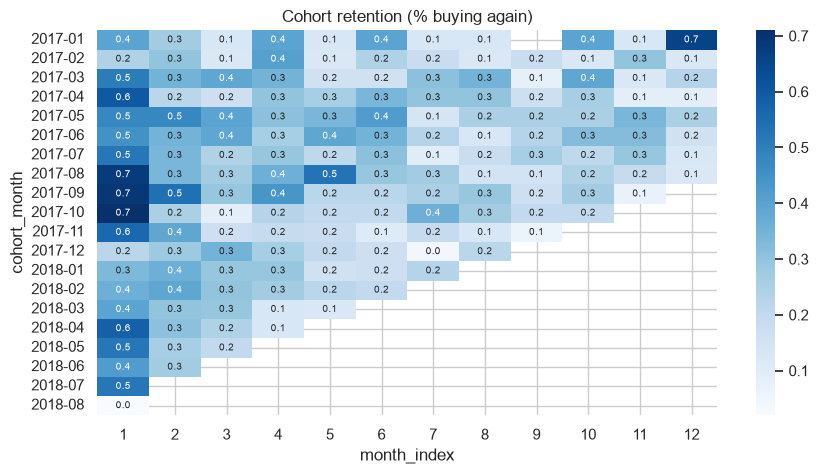

In [10]:
coh = pd.read_csv(ROOT/"data/processed/sql_cohort_retention.csv")
coh = coh[(coh.cohort_size>=300)&(coh.month_index.between(1,12))]
piv = coh.pivot(index="cohort_month", columns="month_index", values="retention_pct")
plt.figure(figsize=(10,5)); sns.heatmap(piv, cmap="Blues", annot=True, fmt=".1f", annot_kws={"size":7}); plt.title("Cohort retention (% buying again)"); plt.show()

## 7. What predicts a bad review? (logistic regression)

In [11]:
import json
ins = json.load(open(ROOT/"reports/insights.json"))
print("Hold-out ROC-AUC:", ins["model"]["auc"])
pd.DataFrame(ins["model"]["odds_ratios"])[["label","odds_ratio_per_sd"]]

Hold-out ROC-AUC: 0.732


,label,odds_ratio_per_sd
0,Total delivery time (days),1.82
1,Items in order,1.56
2,Days late vs promised date,1.32
3,Order value (log),0.99
4,Freight as % of item value,0.97


**Reading the odds ratios:** a value of 1.5 means a one-standard-deviation increase in that feature multiplies the odds of a 1-2 star review by 1.5, holding the others fixed. This shows association, not causation.

## 8. Takeaways
See `reports/insights.md` for the written findings and recommendations (generated from these same numbers), and `reports/dashboard.html` for the interactive dashboard.